# Did the model see Spurs' signings coming?

Six windows: summer 2023, January 2024, summer 2024, January 2025, summer 2025, January 2026. For each one the value model is trained again from scratch and pointed at the players Spurs could have bought that day.

A gap above 1 means the stats implied a higher fee than the market. Percentile 100 is the most undervalued player in that role. "Overpaid" means the fee was higher than the model's value. A loan has no fee to compare.

## What the model was allowed to know

The backtest is only meaningful if nothing from after the window leaks in. Each rule is an assert, and the tests fail if a row breaks it.

1. **Training seasons had already ended.** A season ends on 30 June. Summer windows open on 1 July, so the season that just finished is allowed. The new season is not.
2. **January uses the last completed season only.** FBref's season totals include games played after the window. January 2024 is scored on 2022-23, not on 2023-24. January 2025 uses 2023-24. January 2026 uses 2024-25.
3. **Fees are `value_at_date` on the cutoff, or earlier.** The latest value date in that window's training and scoring tables has to be on or before the day the window opened.
4. **Team strength is rebuilt from those same fees.** It is the leave-one-out average of teammates' values dated on or before the cutoff, not the July 2026 snapshot.
5. **Nothing about how a player did at Spurs is a feature.** Stints at Tottenham are dropped before the features are built. A loan spell at Spurs cannot talk the model into the permanent deal. Minutes at Spurs are used only afterwards, as the outcome.

Two further safeguards. Style labels from the 2025-26 clustering are wiped, because those clusters were fit on a season these windows are not allowed to see. And the player being scored is held out of the fit. A model that had just trained on his own fee would hand that fee back, which would make every summer window look perfectly calibrated.

The transfer file has no loan column. A move is marked a loan when the player goes back to the same club for no fee within two years, or this row is that return. A free permanent transfer, such as Manor Solomon from Shakhtar, stays a free transfer. The senior club in the file is "Tottenham" (club id 148), which is Tottenham Hotspur. Youth teams are left out.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.backtest import WINDOWS, run_backtest

signings, picks, pool = run_backtest()
print(f"{len(signings)} arrivals, {int(signings['scorable'].sum())} the model could score.")
print(f"{len(picks)} alternative picks across the roles Spurs bought.")

Summer 2023: training on seasons that ended before 2023-07-01


Feature list: goals_per90, non_penalty_goals_per90, assists_per90, shots_per90, shots_on_target_per90, crosses_per90, tackles_won_per90, interceptions_per90, fouls_committed_per90, fouls_drawn_per90, offsides_per90, shot_accuracy, goals_per_shot


Feature list: goals_per90, non_penalty_goals_per90, assists_per90, shots_per90, shots_on_target_per90, crosses_per90, tackles_won_per90, interceptions_per90, fouls_committed_per90, fouls_drawn_per90, offsides_per90, shot_accuracy, goals_per_shot
  feature season 2223, 1423 training rows, 1423 scored


January 2024: training on seasons that ended before 2024-01-01


Feature list: goals_per90, non_penalty_goals_per90, assists_per90, shots_per90, shots_on_target_per90, crosses_per90, tackles_won_per90, interceptions_per90, fouls_committed_per90, fouls_drawn_per90, offsides_per90, shot_accuracy, goals_per_shot


Feature list: goals_per90, non_penalty_goals_per90, assists_per90, shots_per90, shots_on_target_per90, crosses_per90, tackles_won_per90, interceptions_per90, fouls_committed_per90, fouls_drawn_per90, offsides_per90, shot_accuracy, goals_per_shot
  feature season 2223, 1423 training rows, 1423 scored


... (9 outputs left out)

January 2026: training on seasons that ended before 2026-01-01


Feature list: goals_per90, non_penalty_goals_per90, assists_per90, shots_per90, shots_on_target_per90, crosses_per90, tackles_won_per90, interceptions_per90, fouls_committed_per90, fouls_drawn_per90, offsides_per90, shot_accuracy, goals_per_shot


Feature list: goals_per90, non_penalty_goals_per90, assists_per90, shots_per90, shots_on_target_per90, crosses_per90, tackles_won_per90, interceptions_per90, fouls_committed_per90, fouls_drawn_per90, offsides_per90, shot_accuracy, goals_per_shot
  feature season 2425, 4200 training rows, 1371 scored


Wrote 38 signings to /Users/samvitchoudhary/Desktop/spurs-moneyball/data/processed/backtest_signings.csv
Wrote 60 model picks to /Users/samvitchoudhary/Desktop/spurs-moneyball/data/processed/backtest_model_picks.csv
38 arrivals, 13 the model could score.
60 alternative picks across the roles Spurs bought.


## Each window

Scorable means he had 900 minutes in a top-5 league in the last completed season, outside Tottenham. Everyone else is kept in the table. Value change is the fee one year later divided by the fee on the day the window opened. A hit is at least half of Spurs' league minutes and a higher fee. A miss is under a quarter of the minutes, or a fee down more than 25%. January 2026 has no year of value yet.

In [2]:
def _eur(value):
    if pd.isna(value):
        return ""
    return f"€{value / 1e6:.1f}m"


def _pct(log_change):
    if pd.isna(log_change):
        return ""
    return f"{(np.exp(log_change) - 1) * 100:+.0f}%"


def _window_table(frame):
    show = pd.DataFrame({
        "Player": frame["player"],
        "From": frame["from_club"],
        "Fee": frame["fee_eur"].map(_eur),
        "Loan": frame["is_loan"].map(lambda flag: "yes" if flag else ""),
        "Role": frame["position_group"].fillna(""),
        "Scorable": frame["scorable"].map(lambda flag: "yes" if flag else "no"),
        "Why not": frame["not_scorable_reason"].fillna(""),
        "Value at window": frame["value_at_cutoff"].map(_eur),
        "Model": frame["model_value"].map(_eur),
        "Gap": frame["value_gap"].map(lambda value: "" if pd.isna(value) else f"{value:.2f}x"),
        "Percentile": frame["gap_percentile"].map(lambda value: "" if pd.isna(value) else f"{value:.0f}"),
        "Fee vs model": frame["overpaid_vs_model"].fillna(""),
        "Minutes": frame["minutes"].map(lambda value: "" if pd.isna(value) else f"{value:.0f}"),
        "Share": frame["minutes_share"].map(lambda value: "" if pd.isna(value) else f"{100 * value:.0f}%"),
        "Value change": frame["log_value_change"].map(_pct),
        "Outcome": frame["outcome"],
    })
    return show


for window in WINDOWS:
    block = signings.loc[signings["window"] == window.name]
    display(Markdown(f"### {window.name}"))
    display(_window_table(block))

### Summer 2023

,Player,From,Fee,Loan,Role,Scorable,Why not,Value at window,Model,Gap,Percentile,Fee vs model,Minutes,Share,Value change,Outcome
0,James Maddison,Leicester,€46.3m,,AM_W,yes,,€60.0m,€33.6m,0.56x,13,yes,2135,62%,+17%,hit
1,Micky van de Ven,Wolfsburg,€40.0m,,CB,yes,,€30.0m,€21.3m,0.71x,22,yes,2339,68%,+83%,hit
2,Brennan Johnson,Nott'm Forest,€55.0m,,AM_W,yes,,€38.0m,€23.6m,0.62x,16,yes,2085,61%,+26%,hit
3,Dane Scarlett,Tottenham U21,,,ST,no,no 900-minute season in a top-5 league before ...,,,,,,22,1%,+0%,miss
4,Dejan Kulusevski,Juventus,€30.0m,,AM_W,no,the only top-5 minutes before the window were ...,,,,,,2762,81%,+10%,hit
5,Guglielmo Vicario,FC Empoli,€18.5m,,GK,no,goalkeeper: the model does not price them,,,,,,3420,100%,+119%,hit
6,Pedro Porro,Sporting,€40.0m,,FB,no,the only top-5 minutes before the window were ...,,,,,,3089,90%,+12%,hit
7,Manor Solomon,Shakhtar D.,€0.0m,,AM_W,no,no 900-minute season in a top-5 league before ...,,,,,,199,6%,-28%,miss
8,Ashley Phillips,Blackburn,€2.3m,,CB,no,no 900-minute season in a top-5 league before ...,,,,,,0,0%,+10%,miss
9,Alejo Veliz,Rosario Central,€15.0m,,ST,no,no 900-minute season in a top-5 league before ...,,,,,,50,1%,+125%,miss


### January 2024

,Player,From,Fee,Loan,Role,Scorable,Why not,Value at window,Model,Gap,Percentile,Fee vs model,Minutes,Share,Value change,Outcome
10,Timo Werner,Leipzig,€0.0m,yes,ST,yes,,€17.0m,€39.1m,2.30x,88,loan,516,15%,-12%,miss
11,Djed Spence,Leeds,€0.0m,yes,FB,no,"Tottenham minutes were removed, and what was l...",,,,,loan,1792,52%,+0%,mixed
12,Sergio Reguilón,Man Utd,€0.0m,yes,FB,no,no 900-minute season in a top-5 league before ...,,,,,loan,196,6%,+10%,miss
13,Radu Drăgușin,Genoa,€28.0m,,CB,no,no 900-minute season in a top-5 league before ...,,,,,,1252,37%,+25%,mixed
14,Japhet Tanganga,FC Augsburg,€0.0m,yes,CB,no,the only top-5 minutes before the window were ...,,,,,loan,0,0%,-40%,miss


### Summer 2024

,Player,From,Fee,Loan,Role,Scorable,Why not,Value at window,Model,Gap,Percentile,Fee vs model,Minutes,Share,Value change,Outcome
15,Dominic Solanke,Bournemouth,€64.3m,,ST,yes,,€40.0m,€45.3m,1.13x,59,yes,2201,64%,+0%,mixed
16,Wilson Odobert,Burnley,€29.3m,,AM_W,yes,,€10.0m,€23.5m,2.35x,98,yes,850,25%,+100%,miss
17,Alfie Devine,Tottenham U21,,,AM_W,no,no 900-minute season in a top-5 league before ...,,,,,,0,0%,+59%,miss
18,Lucas Bergvall,Djurgården,€20.0m,,CM,no,no 900-minute season in a top-5 league before ...,,,,,,1212,35%,+280%,mixed
19,Mikey Moore,Spurs U18,,,AM_W,no,the only top-5 minutes before the window were ...,,,,,,366,11%,,miss
20,Archie Gray,Leeds,€41.2m,,CM,no,no 900-minute season in a top-5 league before ...,,,,,,1751,51%,+111%,hit


... (2 outputs left out)

### Summer 2025

,Player,From,Fee,Loan,Role,Scorable,Why not,Value at window,Model,Gap,Percentile,Fee vs model,Minutes,Share,Value change,Outcome
26,Kevin Danso,Lens,€25.0m,,CB,yes,,€25.0m,€9.8m,0.39x,2,yes,1494,44%,-20%,mixed
27,Mohammed Kudus,West Ham,€63.8m,,AM_W,yes,,€45.0m,€31.6m,0.70x,19,yes,1535,45%,+11%,mixed
28,Xavi Simons,Leipzig,€65.0m,,AM_W,yes,,€70.0m,€63.3m,0.90x,37,yes,1755,51%,-43%,miss
29,Randal Kolo Muani,PSG,€0.0m,yes,ST,yes,,€30.0m,€32.4m,1.08x,55,loan,1664,49%,-33%,miss
30,Luka Vuskovic,Hajduk Split,€11.0m,,CB,no,no 900-minute season in a top-5 league before ...,,,,,,0,0%,+400%,miss
31,Mathys Tel,Bayern Munich,€35.0m,,ST,no,"Tottenham minutes were removed, and what was l...",,,,,,1349,39%,-37%,miss
32,Kota Takai,Kawasaki Front.,€5.8m,,CB,no,no 900-minute season in a top-5 league before ...,,,,,,0,0%,+100%,miss
33,João Palhinha,Bayern Munich,€0.0m,yes,CM,no,no 900-minute season in a top-5 league before ...,,,,,loan,2198,64%,-50%,miss


### January 2026

,Player,From,Fee,Loan,Role,Scorable,Why not,Value at window,Model,Gap,Percentile,Fee vs model,Minutes,Share,Value change,Outcome
34,Conor Gallagher,Atlético,€40.0m,,CM,yes,,€35.0m,€24.0m,0.69x,21,yes,1184,35%,,too early
35,Manor Solomon,Villarreal,€0.0m,yes,AM_W,no,no 900-minute season in a top-5 league before ...,,,,,loan,0,0%,,too early
36,Min-hyeok Yang,Portsmouth,€0.0m,yes,AM_W,no,no 900-minute season in a top-5 league before ...,,,,,loan,0,0%,,too early
37,Souza,Santos,€15.0m,,FB,no,no 900-minute season in a top-5 league before ...,,,,,,144,4%,,too early


## Fix: the comparison group was older and cheaper than the shortlist

The model's alternatives are aged 27 or under and priced at €2m or more. Comparing them with every player in the role mixed in veterans and players the list is not allowed to pick. The bar that matters is the median change among players who pass the same two filters. The median of the whole role stays in the table next to it.

## Did the model's picks gain value faster?

For every role Spurs bought in that window, the alternatives are the three most undervalued players aged 27 or under and priced at €2m or more. The bars are the median change in market value over the next year. January 2026 is left off: the anniversary has not arrived.

The green bar is players in that role who are also 27 or under and priced at €2m or more. The whole-role median is in the table, not on the chart.

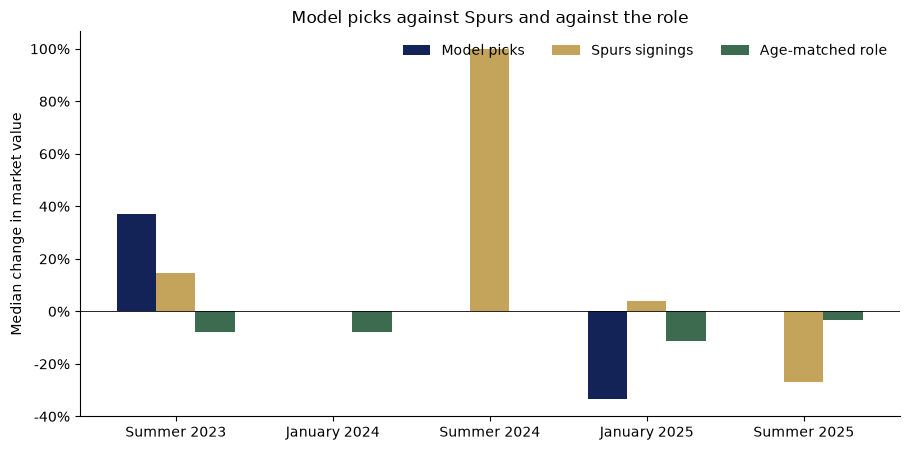

,Model picks,Spurs signings,Age-matched role,Whole role
Window,,,,
Summer 2023,37,15,-8,-17
January 2024,0,0,-8,-17
Summer 2024,0,100,0,-14
January 2025,-33,4,-11,-17
Summer 2025,0,-27,-3,-15


,Median change,Count
Model picks,+0%,51
Spurs signings,+10%,32
Age-matched role,-7%,17
Whole role,-17%,17


Picks ahead of the age-matched median: 47%.
Picks ahead of Spurs' signings in that role: 43%.


In [3]:
def _median_percent(log_changes):
    series = pd.Series(log_changes).dropna()
    if series.empty:
        return np.nan
    return (np.exp(series.median()) - 1) * 100


finished = [window.name for window in WINDOWS if window.name != "January 2026"]
rows = []
for name in finished:
    role_rows = picks.loc[picks["window"] == name].drop_duplicates("position_group")
    rows.append({
        "Window": name,
        "Model picks": _median_percent(picks.loc[picks["window"] == name, "log_value_change"]),
        "Spurs signings": _median_percent(signings.loc[signings["window"] == name, "log_value_change"]),
        "Age-matched role": _median_percent(role_rows["age_matched_median_log_change"]),
        "Whole role": _median_percent(role_rows["position_median_log_change"]),
    })
summary = pd.DataFrame(rows).set_index("Window")

fig, ax = plt.subplots(figsize=(9.2, 4.6))
x = np.arange(len(summary))
width = 0.25
colors = {"Model picks": "#132257", "Spurs signings": "#c4a35a", "Age-matched role": "#3d6b4f", "Whole role": "#b7b1a6"}
# The chart is the matched comparison. The whole-role column stays in the table.
chart_columns = ["Model picks", "Spurs signings", "Age-matched role"]
offsets = (-width, 0, width)
for offset, column in zip(offsets, chart_columns):
    ax.bar(x + offset, summary[column], width, label=column, color=colors[column])
ax.axhline(0, color="black", linewidth=0.6)
ax.set_xticks(x)
ax.set_xticklabels(summary.index)
ax.set_ylabel("Median change in market value")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0f}%"))
ax.set_title("Model picks against Spurs and against the role")
ax.legend(frameon=False, ncol=3, loc="upper right")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()

overall = pd.DataFrame({
    "Median change": [
        _pct(picks["log_value_change"].median()),
        _pct(signings["log_value_change"].median()),
        _pct(picks.drop_duplicates(["window", "position_group"])["age_matched_median_log_change"].median()),
        _pct(picks.drop_duplicates(["window", "position_group"])["position_median_log_change"].median()),
    ],
    "Count": [
        int(picks["log_value_change"].notna().sum()),
        int(signings["log_value_change"].notna().sum()),
        int(picks.drop_duplicates(["window", "position_group"])["age_matched_median_log_change"].notna().sum()),
        int(picks.drop_duplicates(["window", "position_group"])["position_median_log_change"].notna().sum()),
    ],
}, index=["Model picks", "Spurs signings", "Age-matched role", "Whole role"])
display(summary.round(0).astype("Int64"))
display(overall)
compared = picks.loc[picks["log_value_change"].notna()]
beat_role = (compared["log_value_change"] > compared["age_matched_median_log_change"]).mean()
beat_spurs = (compared["log_value_change"] > compared["spurs_median_log_change"]).mean()
print(f"Picks ahead of the age-matched median: {beat_role:.0%}.")
print(f"Picks ahead of Spurs' signings in that role: {beat_spurs:.0%}.")

## Fix: separate a move to a richer club from the model, and separate the first team from the prospects

The alternative picks are ranked by the calibrated gap. For each window the decile adjustment comes from that window's training predictions only. A player's own training gap is left out of his decile mean, and nothing after the cutoff is used.

Moving club is an outcome, not a feature. In the year after the window opened, a player "moved up" if he joined a top-5 club whose squad, priced on the day the window opened, was worth more than the club he left. A move outside the top five is not counted, because those squads are not in the data.

A first-team arrival is a fee of €10m or more, or a loan of someone who already had 900 minutes in a top-5 league the season before. A loan with a thinner season, including Palhinha's, stays a development move. So does a cheap or free permanent.

In [4]:
def _change(frame):
    change = frame["log_value_change"].dropna()
    if change.empty:
        return ""
    return f"{(np.exp(change.median()) - 1) * 100:+.0f}% (n={len(change)})"


finished_pool = pool.loc[pool["log_value_change"].notna()]
age_matched = finished_pool.loc[(finished_pool["age"] <= 27) & (finished_pool["market_value_eur"] >= 2_000_000)]
groups = {
    "Model picks": picks.loc[picks["log_value_change"].notna()],
    "Spurs signings": signings.loc[signings["log_value_change"].notna()],
    "Age-matched role": age_matched,
}
rows = []
for label, frame in groups.items():
    moved = frame["moved_to_stronger_club"].astype(bool)
    rows.append({
        "Group": label,
        "All": _change(frame),
        "Moved up": _change(frame.loc[moved]),
        "Did not move up": _change(frame.loc[~moved]),
    })
display(pd.DataFrame(rows))
tier_counts = pd.crosstab(signings["signing_tier"], signings["outcome"])
display(tier_counts.reindex(columns=["hit", "mixed", "miss", "too early"]))


,Group,All,Moved up,Did not move up
0,Model picks,+0% (n=51),-15% (n=6),+0% (n=45)
1,Spurs signings,+10% (n=32),+10% (n=17),+11% (n=15)
2,Age-matched role,-6% (n=4537),-8% (n=505),-5% (n=4032)


outcome,hit,mixed,miss,too early
signing_tier,,,,
development,0,1,11,2
first-team,7,7,8,2


## Conclusion

The fairness checks take away the result that looked good. The picks' median value change is still 0%. Once the comparison is players in the same role who are also 27 or under and cost at least €2m, that benchmark is about -6% and 47% of the picks beat the bar in their own window. Spurs' arrivals gained +10%. Joining a richer club does not explain it: signings who moved up gained +10%, and signings who did not gained +11%. Among the age-matched players, those who moved up gained slightly less (-8%) than those who stayed (-5%).

All 7 hits were first-team arrivals (7 hits, 7 mixed, 8 misses, 2 too early). Development moves were 0 hits, 1 mixed and 11 misses. The sample is small, 13 scored signings out of 38 arrivals, so this is evidence about these windows, not proof.

## Limitations

The sample is small: 38 arrivals and 13 the model could score. That is evidence, not proof.

Market value a year later is an imperfect measure of a signing. It moves with age, injuries, and the club around the player, and it is not minutes or trophies.

Loans complicate the fees. A zero in the file is not a zero price, Werner and Tel and Kolo Muani arrived on loan and the fee came later, and the file has no loan flag. The label is inferred from a free return to the same club.

Goalkeepers are outside the model, so Vicario is in the outcome table and not in the gap table. January 2026 is too early for a value change. The valuation file ends on 12 June 2026, so the summer 2025 anniversary is about three weeks short of a full year.